In [1]:

!pip install kagglehub[pandas-datasets]

# Loading dataset

In [2]:
import pandas as pd

import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "weatherAUS.csv"

df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "jsphyg/weather-dataset-rattle-package",
  file_path,
)

print("First 5 records:", df.head())

/tmp/ipykernel_18604/2515393277.py:8: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'weather-dataset-rattle-package' dataset.
First 5 records:          Date Location  MinTemp  MaxTemp  Rainfall  Evaporation  Sunshine  \
0  2008-12-01   Albury     13.4     22.9       0.6          NaN       NaN   
1  2008-12-02   Albury      7.4     25.1       0.0          NaN       NaN   
2  2008-12-03   Albury     12.9     25.7       0.0          NaN       NaN   
3  2008-12-04   Albury      9.2     28.0       0.0          NaN       NaN   
4  2008-12-05   Albury     17.5     32.3       1.0          NaN       NaN   

  WindGustDir  WindGustSpeed WindDir9am  ... Humidity9am  Humidity3pm  \
0           W           44.0          W  ...        71.0         22.0   
1         WNW           44.0        NNW  ...        44.0         25.0   
2         WSW           46.0          W  ...        38.0         30.0   
3          NE           24.0         SE  ...        45.0         16.0   
4           W           41.0        ENE  ...        82.0         33.0 

In [3]:
df.describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,143975.000000,144199.000000,142199.000000,82670.000000,75625.000000,135197.000000,143693.000000,142398.000000,142806.000000,140953.000000,130395.00000,130432.000000,89572.000000,86102.000000,143693.000000,141851.00000
mean,12.194034,23.221348,2.360918,5.468232,7.611178,40.035230,14.043426,18.662657,68.880831,51.539116,1017.64994,1015.255889,4.447461,4.509930,16.990631,21.68339
std,6.398495,7.119049,8.478060,4.193704,3.785483,13.607062,8.915375,8.809800,19.029164,20.795902,7.10653,7.037414,2.887159,2.720357,6.488753,6.93665
min,-8.500000,-4.800000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.50000,977.100000,0.000000,0.000000,-7.200000,-5.40000
25%,7.600000,17.900000,0.000000,2.600000,4.800000,31.000000,7.000000,13.000000,57.000000,37.000000,1012.90000,1010.400000,1.000000,2.000000,12.300000,16.60000
50%,12.000000,22.600000,0.000000,4.800000,8.400000,39.000000,13.000000,19.000000,70.000000,52.000000,1017.60000,1015.200000,5.000000,5.000000,16.700000,21.10000
75%,16.900000,28.200000,0.800000,7.400000,10.600000,48.000000,19.000000,24.000000,83.000000,66.000000,1022.40000,1020.000000,7.000000,7.000000,21.600000,26.40000
max,33.900000,48.100000,371.000000,145.000000,14.500000,135.000000,130.000000,87.000000,100.000000,100.000000,1041.00000,1039.600000,9.000000,9.000000,40.200000,46.70000


# First dive boxplot


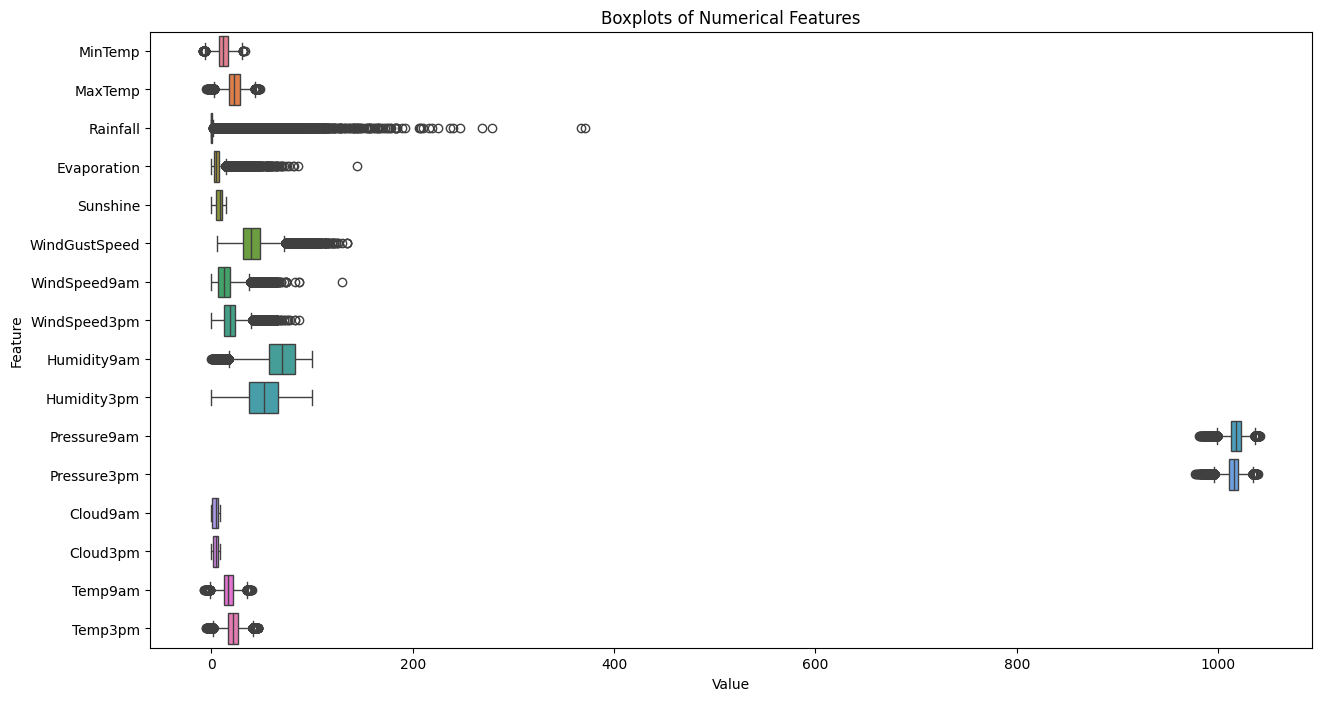

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select only numerical columns for the boxplot
numeric_df = df.select_dtypes(include=['number'])

# Set the figure size for better readability, especially with many columns
plt.figure(figsize=(15, 8))

# Plot boxplots for all numerical columns, oriented horizontally
sns.boxplot(data=numeric_df, orient="h")

plt.title('Boxplots of Numerical Features')
plt.xlabel('Value')
plt.ylabel('Feature')
plt.show()

<Axes: >

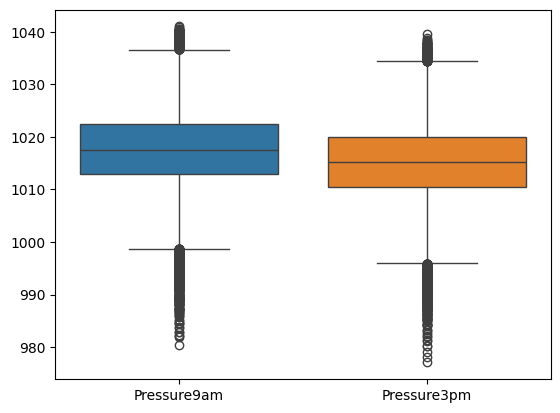

In [ ]:
sns.boxplot(data = df[['Pressure9am','Pressure3pm']])

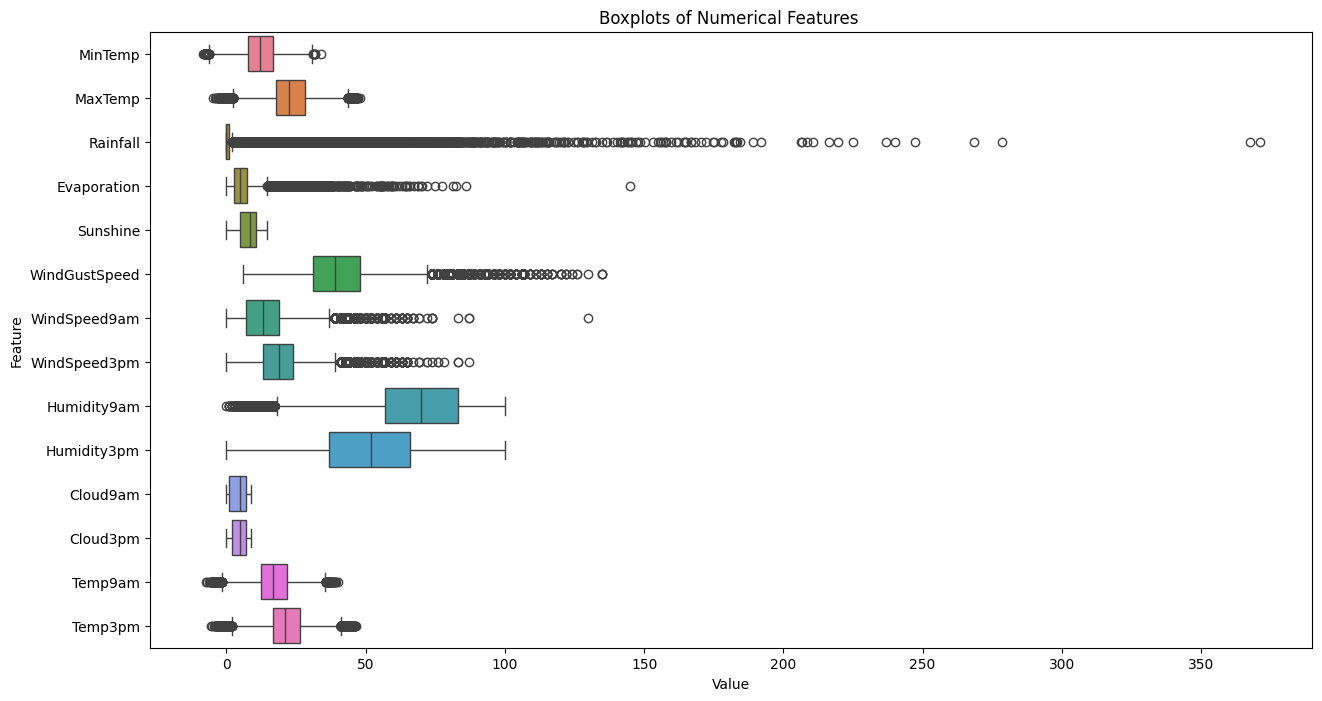

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a new DataFrame by dropping the specified columns
df_filtered = df.drop(columns=['Pressure9am', 'Pressure3pm'])

# Select only numerical columns from the filtered DataFrame
numeric_df_filtered = df_filtered.select_dtypes(include=['number'])

# Set the figure size for better readability
plt.figure(figsize=(15, 8))

# Plot boxplots for the remaining numerical columns
sns.boxplot(data=numeric_df_filtered, orient="h")

plt.title('Boxplots of Numerical Features ')
plt.xlabel('Value')
plt.ylabel('Feature')
plt.show()


#EDA complet checklist

In [ ]:
import missingno as msno

<Axes: >

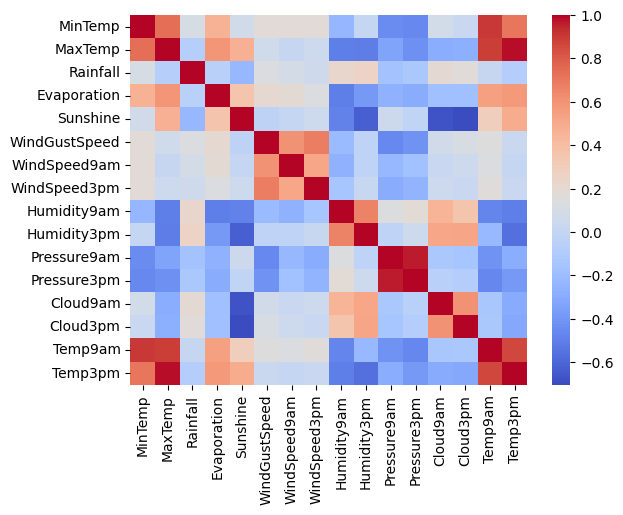

In [ ]:

sns.heatmap(numeric_df.corr(), cmap="coolwarm")

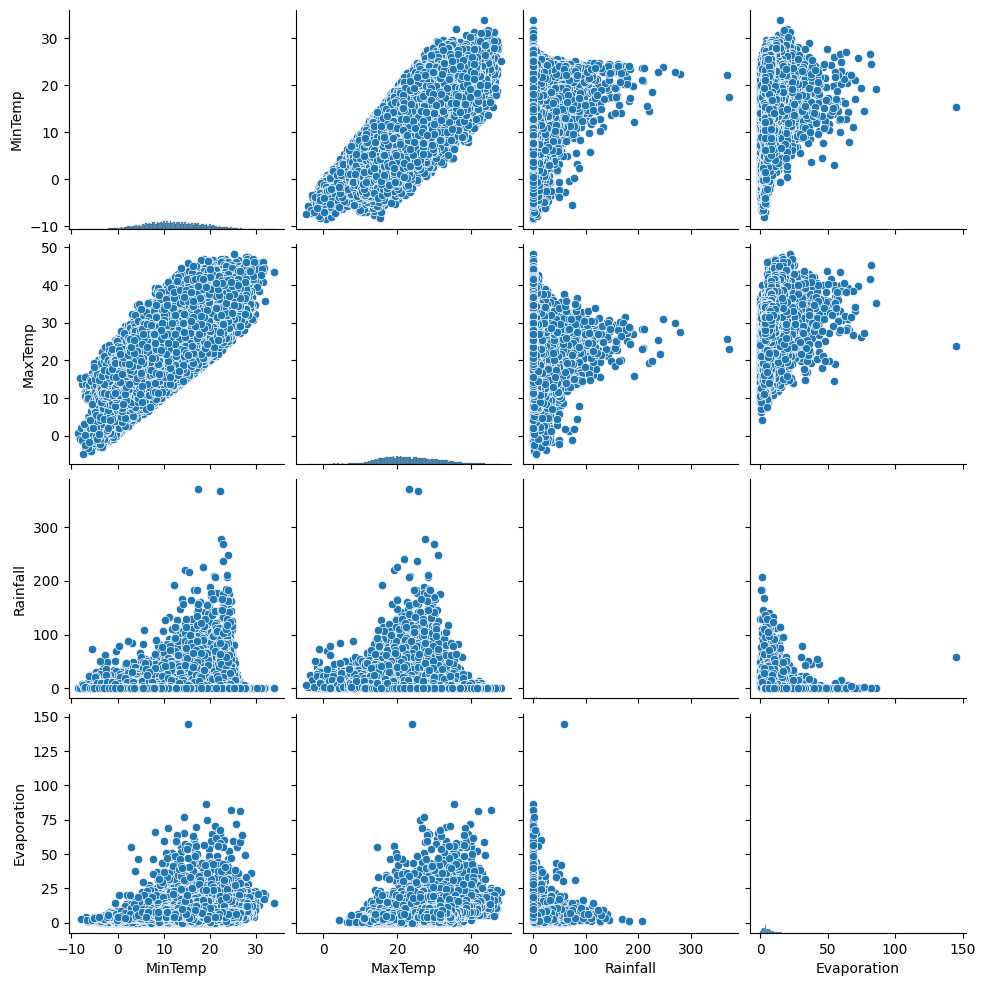

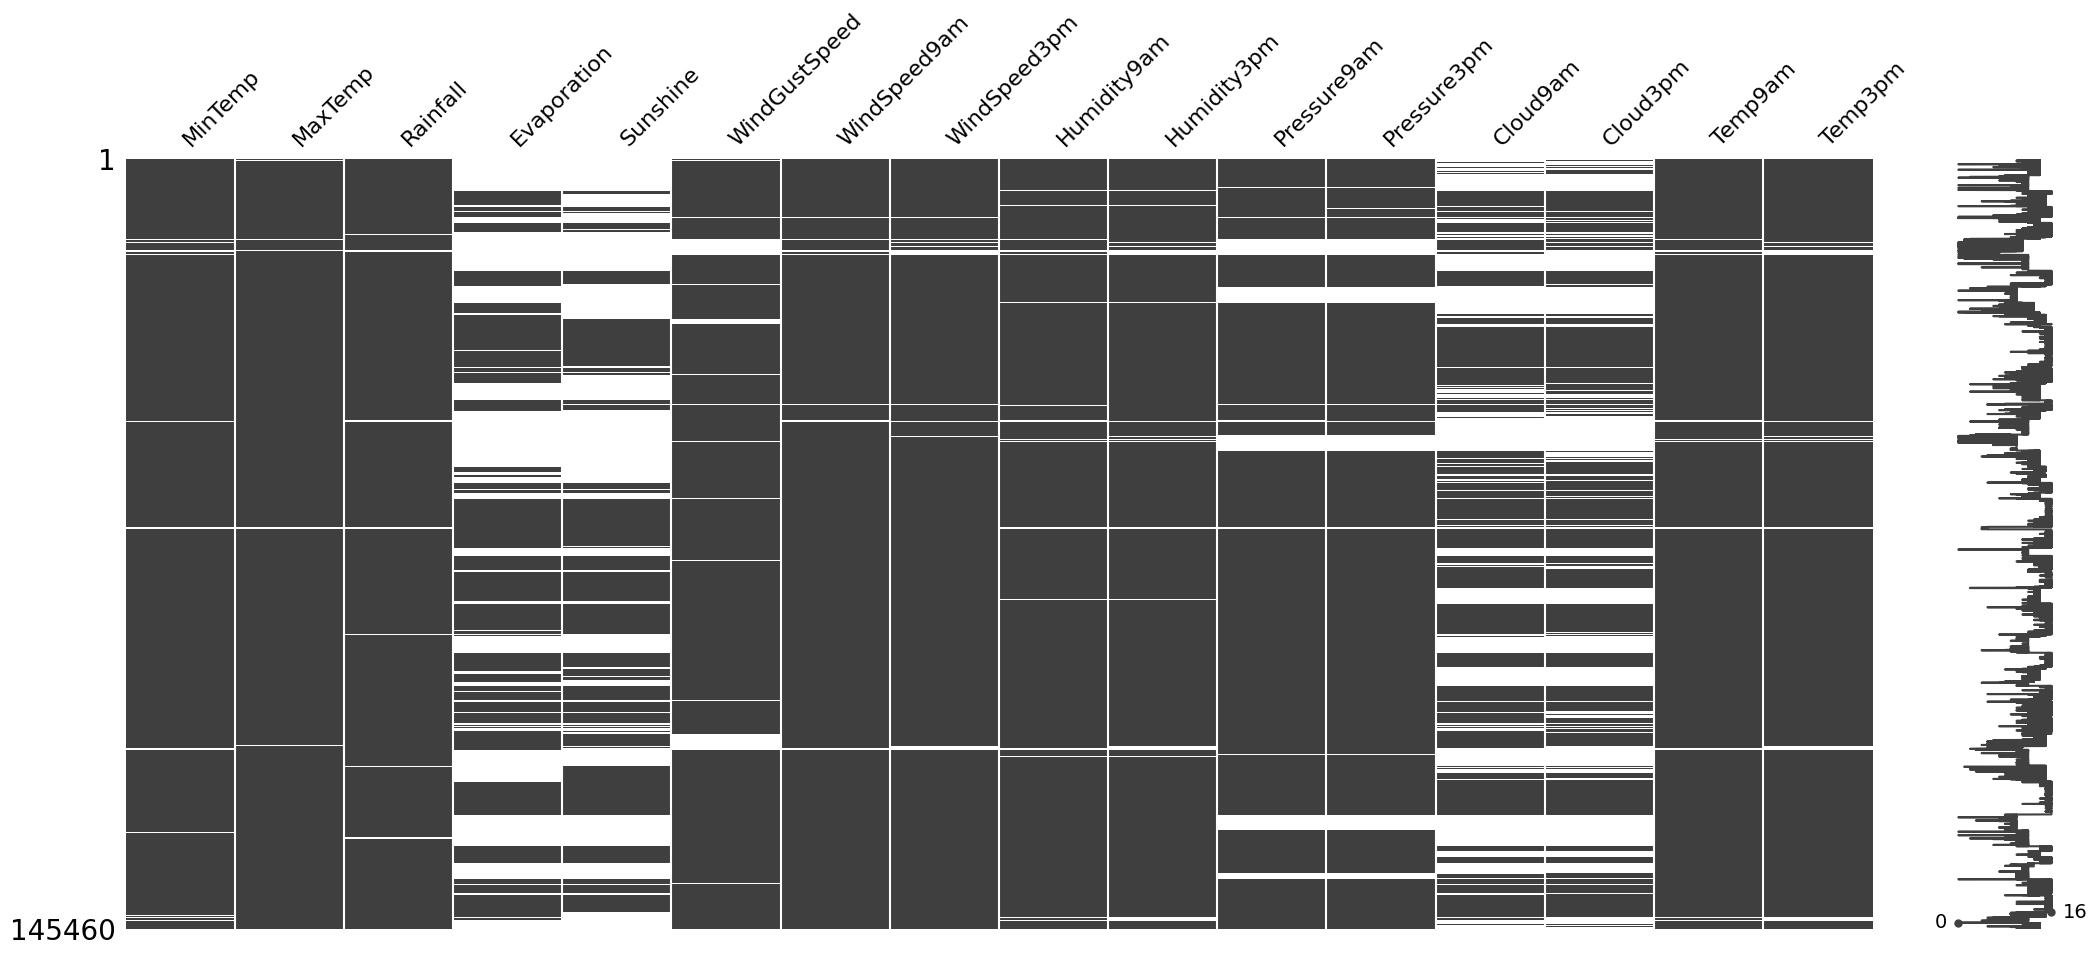

In [ ]:

sns.pairplot(numeric_df.iloc[:, :4])
msno.matrix(numeric_df)
plt.show()

KeyboardInterrupt: 

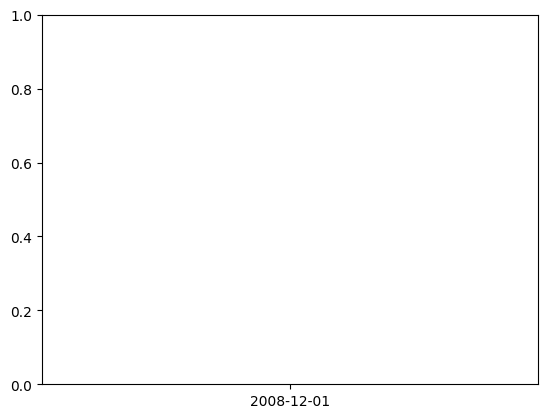

In [ ]:
sns.lineplot(x=df['Date'],y=df['Rainfall'])

#Prophet test no traitement

In [ ]:
from prophet import Prophet
import pandas as pd

df_prophet = df[['Date', 'Rainfall']].rename(columns={'Date': 'ds', 'Rainfall': 'y'})

m = Prophet(
    yearly_seasonality=True,
    daily_seasonality=False,
    weekly_seasonality=False
)

m.fit(df_prophet)

forecast = m.predict(df_prophet)

fig2 = m.plot_components(forecast)  # Tendance + saisonnalités

#Non numeric stats

In [ ]:
from matplotlib import axis
df_non_num = df.drop(numeric_df, axis = 1)
df_non_num = df.drop(numeric_df, axis = 1)
df_non_num.head()

In [ ]:
df['Location'].value_counts()

#Rain by locations stats


In [ ]:
cross = pd.crosstab(df['Location'], df['RainToday'])

In [ ]:
cross.sort_values(by='No',ascending=False).head()

In [ ]:
cross['Total'] = cross['No'] + cross['Yes']
cross['Yes_Ratio'] = cross['Yes'] / cross['Total']
cross.sort_values(by='Yes_Ratio', ascending=True)

In [ ]:
!pip install pyod

In [ ]:
import numpy as np

null_columns_by_location = {}

for location, group in df.groupby('Location'):
    null_cols = []
    for col in group.columns:
        if group[col].isnull().all():
            null_cols.append(col)
    if null_cols:
        null_columns_by_location[location] = null_cols

if null_columns_by_location:
    print("Colonne that is full of NA groupBY locations:")
    for loc, cols in null_columns_by_location.items():
        print(f"Location '{loc}': {', '.join(cols)}")
else:
    print("No columns are entirely null for any location.")

In [ ]:
df

In [ ]:
df_result = df.copy()
df_result["outlier_score"] = 0
df_result["is_outlier"] = 0

from sklearn.preprocessing import StandardScaler
from pyod.models.ecod import ECOD

for loc, group in df.groupby("Location"):

    X = group.select_dtypes(include="number").copy()
        # fillna
    X = X.fillna(X.median())
    # 🔥 nettoyage essentiel
    X = X.dropna(axis=1, how="all")
    X = X.loc[:, X.nunique() > 1]



    # skip si trop petit
    if len(X) < 10 or X.shape[1] == 0:
        continue

    # scaling
    X_scaled = StandardScaler().fit_transform(X)

    # modèle
    clf = ECOD(contamination=0.50)
    clf.fit(X_scaled)

    # assignation
    df_result.loc[group.index, "outlier_score"] = clf.decision_scores_
    df_result.loc[group.index, "is_outlier"] = clf.labels_

In [ ]:
df_result_num = df_result.select_dtypes(include="number")
df_not_out = df_result[df_result_num['is_outlier'] == 0]

In [ ]:
import matplotlib.pyplot as plt

# Iterate through each location group and plot a histogram of 'Rainfall'
for location, data in df_not_out.groupby('Location'):
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=data, x='Rainfall')
    plt.title(f'Rainfall Distribution in {location}')
    plt.xlabel('Rainfall (mm)')
    plt.ylabel('Frequency')
    plt.show()

In [ ]:
df.columns

Index(['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation',
       'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm',
       'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm',
       'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am',
       'Temp3pm', 'RainToday', 'RainTomorrow'],
      dtype='object')

In [ ]:
sub_df_rainfall = df[['RainToday','Rainfall','Location']]

In [ ]:
sub_rain_true = sub_df_rainfall[sub_df_rainfall['RainToday'] == 'Yes']
sub_rain_true.head()

,RainToday,Rainfall,Location
9,Yes,1.4,Albury
11,Yes,2.2,Albury
12,Yes,15.6,Albury
13,Yes,3.6,Albury
17,Yes,16.8,Albury


/tmp/ipykernel_3147/3165962965.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  plot = sns.boxplot(


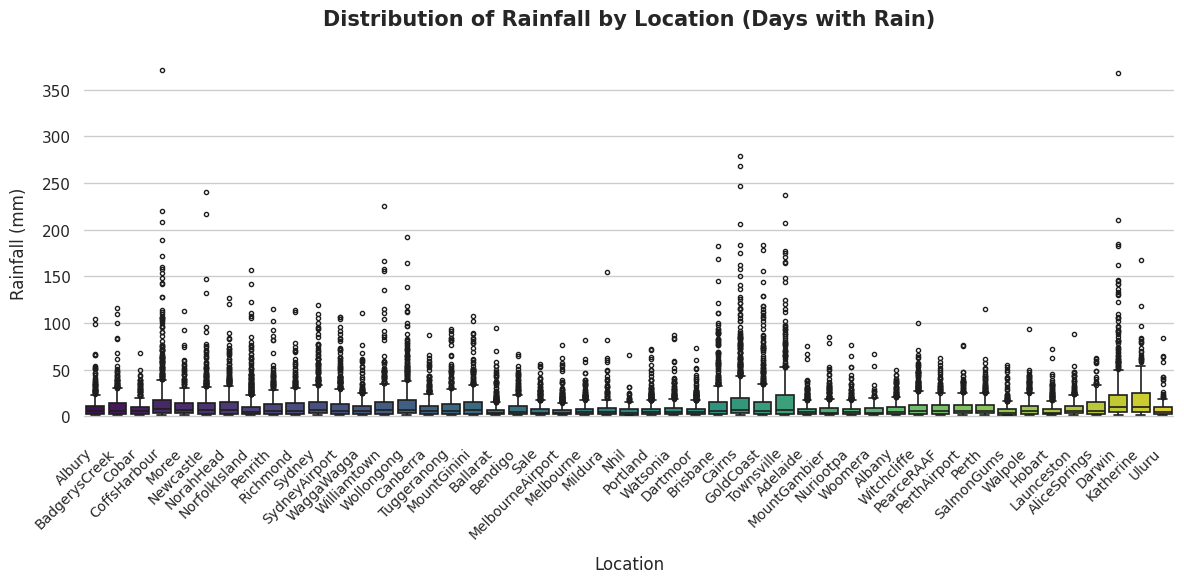

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Configuration du style général
sns.set_theme(style="whitegrid") # Fond propre avec grille légère
plt.figure(figsize=(12, 6))      # On donne de l'air au graphique

# 2. Création du boxplot avec une palette de couleurs plus douce
plot = sns.boxplot(
    x='Location',
    y='Rainfall',
    data=sub_rain_true,
    palette="viridis",          # Palette de couleurs harmonieuse
    linewidth=1.2,              # Traits un peu plus fins
    fliersize=3                 # Taille des points "outliers" réduite
)

# 3. La magie du "Tilted Labels" et de la lisibilité
plt.xticks(
    rotation=45,               # Inclinaison à 45 degrés
    horizontalalignment='right', # Aligne la fin du mot sous le tick
    fontweight='light',
    fontsize=10
)

# 4. Titres et labels élégants
plt.title('Distribution of Rainfall by Location (Days with Rain)', fontsize=15, pad=20, fontweight='bold')
plt.xlabel('Location', fontsize=12, labelpad=10)
plt.ylabel('Rainfall (mm)', fontsize=12, labelpad=10)

# 5. Nettoyage final des bordures (Despine)
sns.despine(left=True, bottom=True)

plt.tight_layout() # Évite que les labels soient coupés au moment de l'affichage
plt.show()

In [4]:
df['Date'] = pd.to_datetime(df['Date'])

df_sorted = df.sort_values(by=['Location', 'Date']).copy()

df_sorted['RainToday_next_day'] = df_sorted.groupby('Location')['RainToday'].shift(-1)

comparison = df_sorted[df_sorted['RainTomorrow'].notna() & df_sorted['RainToday_next_day'].notna()].copy()
comparison['Is_Consistent'] = comparison['RainTomorrow'] == comparison['RainToday_next_day']
inconsistent_records = comparison[comparison['Is_Consistent'] == False]

consistency_rate = comparison['Is_Consistent'].mean() * 100
print(f"\nOverall consistency rate: {consistency_rate:.2f}%")


Overall consistency rate: 100.00%


In [5]:
len(comparison['Is_Consistent'])/len(df)

0.9772583528117695

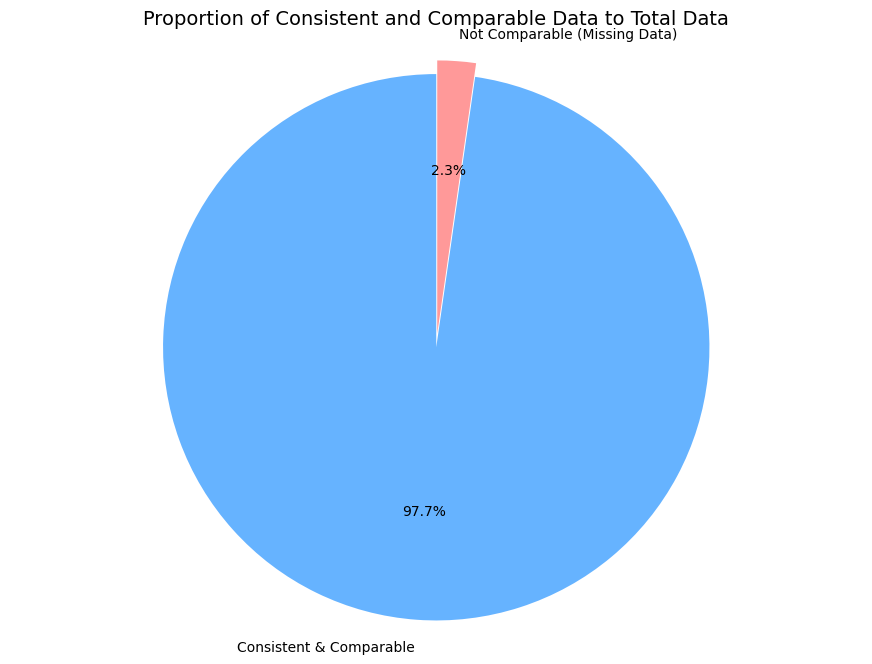

In [8]:
import matplotlib.pyplot as plt

# Number of consistent and comparable records (all records in 'comparison' are consistent as per previous output)
consistent_comparable_count = len(comparison)

# Total number of records in the original DataFrame
total_records_count = len(df)

# Number of records that were not comparable (i.e., RainTomorrow or RainToday_next_day were NaN)
not_comparable_count = total_records_count - consistent_comparable_count

# Data for the pie chart
labels = ['Consistent & Comparable', 'Not Comparable (Missing Data)']
sizes = [consistent_comparable_count, not_comparable_count]
colors = ['#66b3ff', '#ff9999'] # Light blue and light red

# Create the pie chart
plt.figure(figsize=(11, 8))
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90, explode=(0.05, 0)) # Explode one slice for emphasis
plt.title('Proportion of Consistent and Comparable Data to Total Data', fontsize=14)
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()